In [1]:
import pandas as pd

df = pd.read_csv("delivery_operations_students.csv")

print(df.head())
print(df.shape)
print(df.columns)

   order_id  distance_km  delivery_time_min  preparation_time_min  \
0  DLV-0001          2.2                 14                    22   
1  DLV-0002          2.1                 17                    12   
2  DLV-0003          2.2                 12                     8   
3  DLV-0004          2.0                 22                    11   
4  DLV-0005          9.8                 50                    22   

   order_value_egp  
0              206  
1              190  
2              119  
3              113  
4              292  
(233, 5)
Index(['order_id', 'distance_km', 'delivery_time_min', 'preparation_time_min',
       'order_value_egp'],
      dtype='str')


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN

df = pd.read_csv("delivery_operations_students.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
print(df.head())

print("\nColumn Names:")
print(df.columns)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Shape: (233, 5)

First 5 Rows:
   order_id  distance_km  delivery_time_min  preparation_time_min  \
0  DLV-0001          2.2                 14                    22   
1  DLV-0002          2.1                 17                    12   
2  DLV-0003          2.2                 12                     8   
3  DLV-0004          2.0                 22                    11   
4  DLV-0005          9.8                 50                    22   

   order_value_egp  
0              206  
1              190  
2              119  
3              113  
4              292  

Column Names:
Index(['order_id', 'distance_km', 'delivery_time_min', 'preparation_time_min',
       'order_value_egp'],
      dtype='str')

Missing Values:
order_id                0
distance_km             0
delivery_time_min       0
preparation_time_min    0
order_value_egp         0
dtype: int64

Duplicate Rows: 0


In [3]:
features = ["distance_km", "delivery_time_min"]

df = df.dropna(subset=features).copy()

X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original Data Shape:", X.shape)
print("Scaled Data Shape:", X_scaled.shape)

Original Data Shape: (233, 2)
Scaled Data Shape: (233, 2)


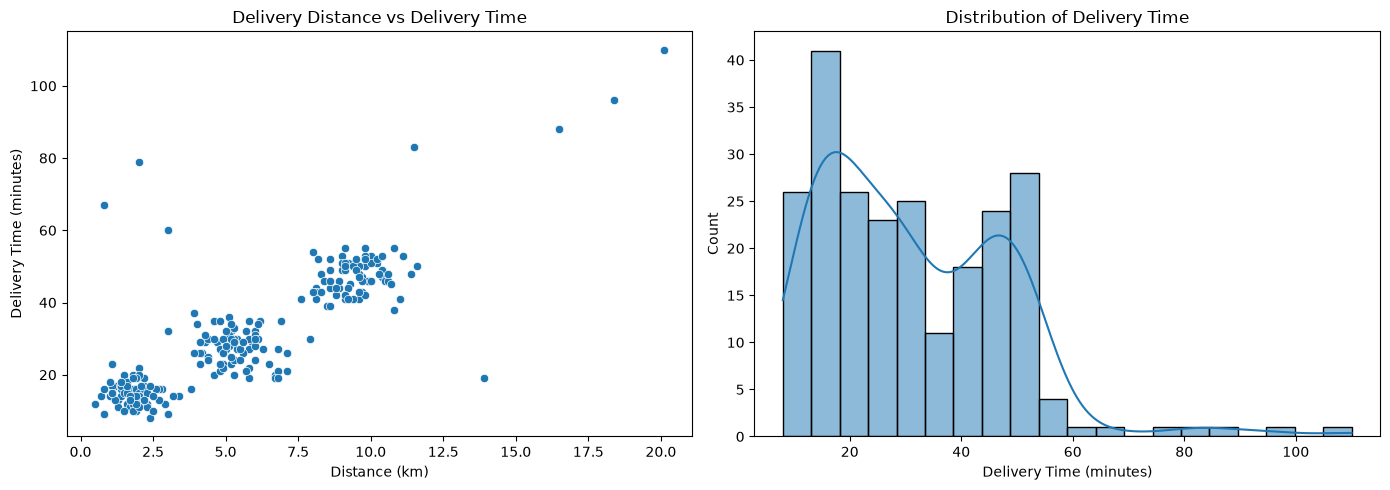

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=df,
    x="distance_km",
    y="delivery_time_min",
    ax=axes[0]
)
axes[0].set_title("Delivery Distance vs Delivery Time")
axes[0].set_xlabel("Distance (km)")
axes[0].set_ylabel("Delivery Time (minutes)")

sns.histplot(
    data=df,
    x="delivery_time_min",
    bins=20,
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Distribution of Delivery Time")
axes[1].set_xlabel("Delivery Time (minutes)")

plt.tight_layout()
plt.show()

Number of Orders in Each K-Means Cluster:
KMeans_Cluster
0    75
1    82
2    76
Name: count, dtype: int64


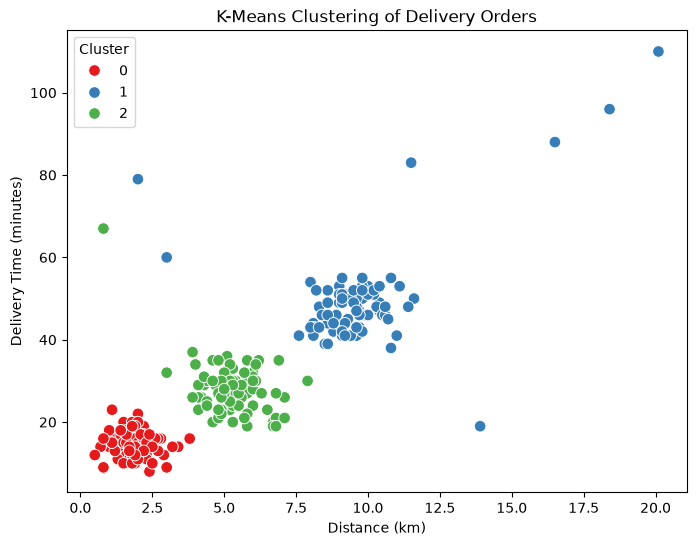

In [5]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

cluster_counts = df["KMeans_Cluster"].value_counts().sort_index()

print("Number of Orders in Each K-Means Cluster:")
print(cluster_counts)

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=X["distance_km"],
    y=X["delivery_time_min"],
    hue=df["KMeans_Cluster"],
    palette="Set1",
    s=70
)

plt.title("K-Means Clustering of Delivery Orders")
plt.xlabel("Distance (km)")
plt.ylabel("Delivery Time (minutes)")
plt.legend(title="Cluster")
plt.show()

In [6]:
print(
    df.groupby("KMeans_Cluster")[
        ["distance_km", "delivery_time_min"]
    ].mean().round(2)
)

                distance_km  delivery_time_min
KMeans_Cluster                                
0                      1.88              14.69
1                      9.66              49.70
2                      5.30              28.11


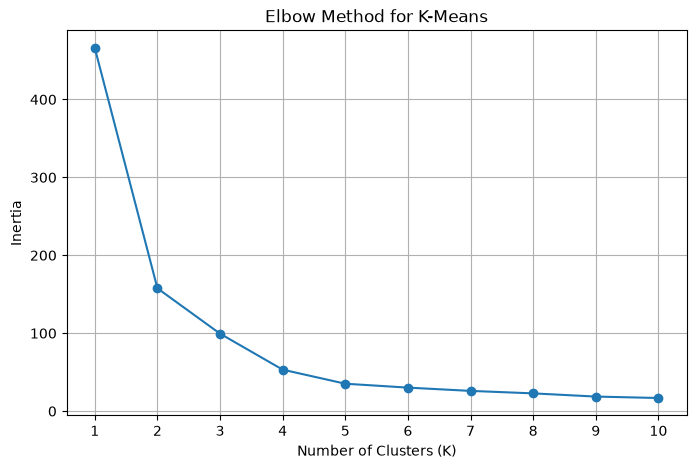

K = 1, Inertia = 466.00
K = 2, Inertia = 157.61
K = 3, Inertia = 99.42
K = 4, Inertia = 53.23
K = 5, Inertia = 35.20
K = 6, Inertia = 30.18
K = 7, Inertia = 25.99
K = 8, Inertia = 22.80
K = 9, Inertia = 18.70
K = 10, Inertia = 16.87


In [7]:
inertias = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")

plt.title("Elbow Method for K-Means")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

for k, inertia in zip(k_values, inertias):
    print(f"K = {k}, Inertia = {inertia:.2f}")

Number of Orders in Each DBSCAN Cluster:
DBSCAN_Cluster
-1    11
 0    75
 1    74
 2    73
Name: count, dtype: int64


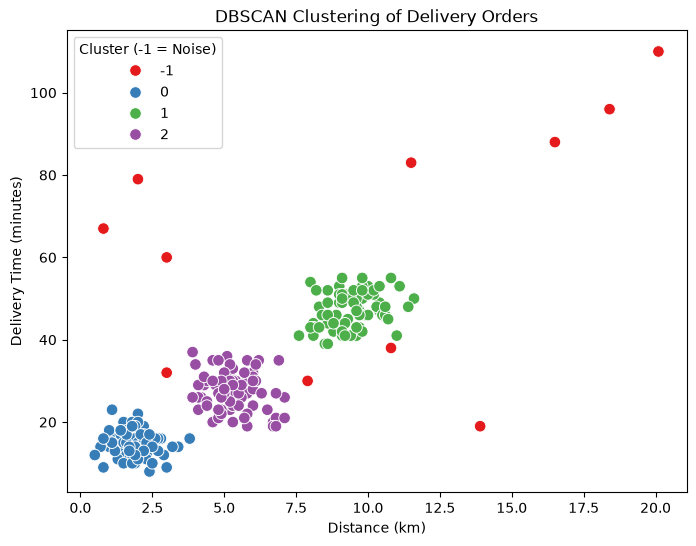

In [8]:
dbscan = DBSCAN(
    eps=0.3,
    min_samples=5
)

df["DBSCAN_Cluster"] = dbscan.fit_predict(X_scaled)

print("Number of Orders in Each DBSCAN Cluster:")
print(df["DBSCAN_Cluster"].value_counts().sort_index())

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=X["distance_km"],
    y=X["delivery_time_min"],
    hue=df["DBSCAN_Cluster"],
    palette="Set1",
    s=70
)

plt.title("DBSCAN Clustering of Delivery Orders")
plt.xlabel("Distance (km)")
plt.ylabel("Delivery Time (minutes)")
plt.legend(title="Cluster (-1 = Noise)")
plt.show()

In [9]:
labels = df["DBSCAN_Cluster"].to_numpy()
core_indices = set(dbscan.core_sample_indices_)

core_count = len(core_indices)

noise_count = np.sum(labels == -1)

border_count = sum(
    1
    for i, label in enumerate(labels)
    if label != -1 and i not in core_indices
)

cluster_count = len(set(labels) - {-1})

print("Number of Clusters:", cluster_count)
print("Core Points:", core_count)
print("Border Points:", border_count)
print("Noise Points:", noise_count)
print("Total Points:", len(labels))

Number of Clusters: 3
Core Points: 215
Border Points: 7
Noise Points: 11
Total Points: 233


In [10]:
eps_values = [0.2, 0.3, 0.4, 0.5, 0.7, 1.0]

for eps_value in eps_values:
    model = DBSCAN(
        eps=eps_value,
        min_samples=5
    )

    labels = model.fit_predict(X_scaled)

    n_clusters = len(set(labels) - {-1})
    n_noise = np.sum(labels == -1)

    print(
        f"eps={eps_value}: "
        f"Clusters={n_clusters}, "
        f"Noise Points={n_noise}"
    )

eps=0.2: Clusters=4, Noise Points=19
eps=0.3: Clusters=3, Noise Points=11
eps=0.4: Clusters=2, Noise Points=8
eps=0.5: Clusters=1, Noise Points=8
eps=0.7: Clusters=1, Noise Points=8
eps=1.0: Clusters=1, Noise Points=8


In [11]:
min_samples_values = [3, 5, 8, 10, 15]

for min_samples_value in min_samples_values:
    model = DBSCAN(
        eps=0.3,
        min_samples=min_samples_value
    )

    labels = model.fit_predict(X_scaled)

    n_clusters = len(set(labels) - {-1})
    n_noise = np.sum(labels == -1)

    print(
        f"min_samples={min_samples_value}: "
        f"Clusters={n_clusters}, "
        f"Noise Points={n_noise}"
    )

min_samples=3: Clusters=3, Noise Points=10
min_samples=5: Clusters=3, Noise Points=11
min_samples=8: Clusters=3, Noise Points=11
min_samples=10: Clusters=3, Noise Points=12
min_samples=15: Clusters=3, Noise Points=18


In [12]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

dbscan = DBSCAN(
    eps=0.3,
    min_samples=5
)

dbscan_labels = dbscan.fit_predict(X_scaled)

kmeans_clusters = len(set(kmeans_labels))
dbscan_clusters = len(set(dbscan_labels) - {-1})

kmeans_noise = 0
dbscan_noise = np.sum(dbscan_labels == -1)

comparison = pd.DataFrame({
    "Algorithm": ["K-Means", "DBSCAN"],
    "Number of Clusters": [
        kmeans_clusters,
        dbscan_clusters
    ],
    "Noise Points": [
        kmeans_noise,
        dbscan_noise
    ]
})

print(comparison)

  Algorithm  Number of Clusters  Noise Points
0   K-Means                   3             0
1    DBSCAN                   3            11


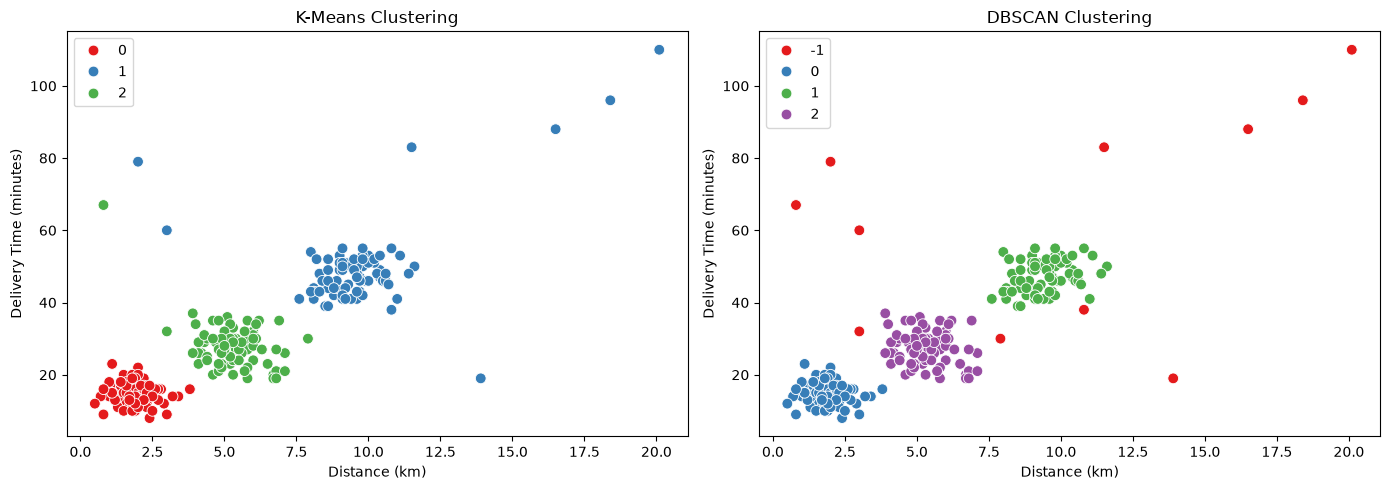

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    x=X["distance_km"],
    y=X["delivery_time_min"],
    hue=kmeans_labels,
    palette="Set1",
    s=60,
    ax=axes[0]
)

axes[0].set_title("K-Means Clustering")
axes[0].set_xlabel("Distance (km)")
axes[0].set_ylabel("Delivery Time (minutes)")

sns.scatterplot(
    x=X["distance_km"],
    y=X["delivery_time_min"],
    hue=dbscan_labels,
    palette="Set1",
    s=60,
    ax=axes[1]
)

axes[1].set_title("DBSCAN Clustering")
axes[1].set_xlabel("Distance (km)")
axes[1].set_ylabel("Delivery Time (minutes)")

plt.tight_layout()
plt.show()